# Boxes and masks on a real photo

Booster LEAP, Computer Vision, topic 5. How good is a box or a mask? We score a colour rule against truth drawn by hand, and change the rule to see what happens.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

## 1. The photo and the truth drawn by hand

No trained detector is used here. The truth is a box and an ellipse **drawn by hand** on the flower photo (read off a coordinate grid); the predictions come from a simple colour rule. Everything is computed, so you can change it.

flower shape (height, width, channels): (427, 640, 3)  dtype: uint8  values 0 to 255


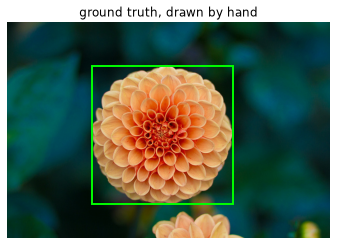

In [ ]:
import io, urllib.request
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/computer-vision/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}

def load_photo(name):
    """one of the three photos of the course, as a PIL image"""
    data = urllib.request.urlopen(BASE + FILES[name]).read()
    return Image.open(io.BytesIO(data)).convert("RGB")

# Your own photo (optional): remove the # signs, run the cell, choose a file.
# from google.colab import files
# photo = Image.open(next(iter(files.upload()))).convert("RGB")

NAME = "flower"          # change to "flower" or "hopper"
photo = load_photo(NAME)
img = np.asarray(photo)
print(NAME, "shape (height, width, channels):", img.shape, " dtype:", img.dtype, " values", img.min(), "to", img.max())

GT_BOX = (168, 85, 447, 360)        # the big flower, drawn by hand: (x1, y1, x2, y2) in pixels
def show_boxes(boxes, colors, title):
    plt.figure(figsize=(6, 4)); plt.imshow(img)
    for (x1, y1, x2, y2), c in zip(boxes, colors):
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=2))
    plt.axis("off"); plt.title(title); plt.show()
show_boxes([GT_BOX], ["lime"], "ground truth, drawn by hand")

## 2. IoU of two boxes

Intersection over union: the area both boxes share divided by the area they cover together. 1 is a perfect match, 0 means no overlap.

In [ ]:
def box_iou(a, b):
    iw = min(a[2], b[2]) - max(a[0], b[0]); ih = min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0:
        return 0.0
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

for dx in (0, 20, 60, 120, 200):
    shifted = (GT_BOX[0] + dx, GT_BOX[1], GT_BOX[2] + dx, GT_BOX[3])
    print(f"the truth box moved {dx:3d} pixels sideways: IoU {box_iou(GT_BOX, shifted):.3f}")

the truth box moved   0 pixels sideways: IoU 1.000
the truth box moved  20 pixels sideways: IoU 0.866
the truth box moved  60 pixels sideways: IoU 0.646
the truth box moved 120 pixels sideways: IoU 0.398
the truth box moved 200 pixels sideways: IoU 0.165


## 3. A colour rule as a detector, and non-maximum suppression

The rule marks orange petal pixels. We slide square windows of four sizes over the photo (step 10 pixels) and score each window: the share of petal pixels inside minus the share in a ring around it. Many windows cover the same flower; non-maximum suppression (NMS) keeps the best and drops windows that overlap it too much.

2732 windows tried, 491 with a score of at least 0.3
NMS with IoU limit 0.7: 24 boxes kept, best IoU with the hand-drawn box 0.807
NMS with IoU limit 0.5: 6 boxes kept, best IoU with the hand-drawn box 0.751
NMS with IoU limit 0.3: 1 boxes kept, best IoU with the hand-drawn box 0.751
NMS with IoU limit 0.1: 1 boxes kept, best IoU with the hand-drawn box 0.751


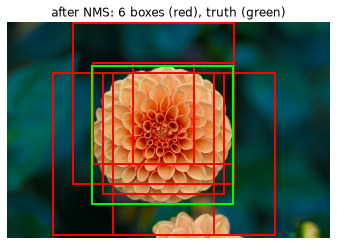

In [ ]:
RED_MIN, RED_OVER_BLUE, GREEN_MIN = 140, 50, 60          # the colour rule: change these numbers later
im16 = img.astype(int)
petal = (im16[..., 0] > RED_MIN) & (im16[..., 0] - im16[..., 2] > RED_OVER_BLUE) & (im16[..., 1] > GREEN_MIN)
integral = np.pad(petal.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
Hh, Ww = petal.shape
def share(x1, y1, x2, y2):
    x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, Ww), min(y2, Hh)
    area = (x2 - x1) * (y2 - y1)
    return (integral[y2, x2] - integral[y1, x2] - integral[y2, x1] + integral[y1, x1]) / area if area > 0 else 0.0

windows = []
for size in (200, 240, 280, 320):
    margin = size // 5
    for y in range(0, Hh - size + 1, 10):
        for x in range(0, Ww - size + 1, 10):
            inner = share(x, y, x + size, y + size)
            outer = share(x - margin, y - margin, x + size + margin, y + size + margin)
            ring = (outer * (min(x + size + margin, Ww) - max(x - margin, 0)) * (min(y + size + margin, Hh) - max(y - margin, 0)) - inner * size * size) / max(
                (min(x + size + margin, Ww) - max(x - margin, 0)) * (min(y + size + margin, Hh) - max(y - margin, 0)) - size * size, 1)
            windows.append(((x, y, x + size, y + size), inner - ring))
windows.sort(key=lambda w: -w[1])
good = [w for w in windows if w[1] >= 0.3]
def nms(items, limit):
    kept = []
    for b, s in items:
        if all(box_iou(b, k) < limit for k, _ in kept):
            kept.append((b, s))
    return kept
print(f"{len(windows)} windows tried, {len(good)} with a score of at least 0.3")
for limit in (0.7, 0.5, 0.3, 0.1):
    kept = nms(good, limit)
    print(f"NMS with IoU limit {limit}: {len(kept)} boxes kept, best IoU with the hand-drawn box {max(box_iou(b, GT_BOX) for b, _ in kept):.3f}")
best = nms(good, 0.5)
show_boxes([b for b, _ in best] + [GT_BOX], ["red"] * len(best) + ["lime"], f"after NMS: {len(best)} boxes (red), truth (green)")

## 4. A mask against an ellipse drawn by hand

The mask is the colour rule, cleaned up (small gaps closed, holes filled). The truth is an ellipse inside the hand-drawn box. TP are pixels in both, FP only in the prediction, FN only in the truth. IoU = TP / (TP + FP + FN) and Dice = 2 TP / (2 TP + FP + FN). A mask of all background has high accuracy but IoU 0: look at the last line.

TP 58305, FP 313, FN 1952: IoU 0.963, Dice 0.981, pixel accuracy 0.992
a mask of all background: IoU 0.000, Dice 0.000, pixel accuracy 0.780


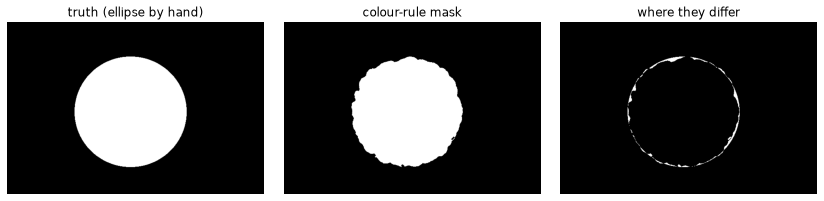

In [ ]:
from scipy import ndimage
mask = ndimage.binary_fill_holes(ndimage.binary_closing(petal, iterations=2))
lab, n = ndimage.label(mask)
sizes = ndimage.sum(mask, lab, range(1, n + 1))
mask = lab == (1 + int(np.argmax(sizes)))               # keep the biggest connected group: the big flower
yy, xx = np.mgrid[0:Hh, 0:Ww]
cx, cy, ax_, ay_ = (GT_BOX[0] + GT_BOX[2]) / 2, (GT_BOX[1] + GT_BOX[3]) / 2, (GT_BOX[2] - GT_BOX[0]) / 2, (GT_BOX[3] - GT_BOX[1]) / 2
truth = ((xx + 0.5 - cx) / ax_) ** 2 + ((yy + 0.5 - cy) / ay_) ** 2 <= 1
def mask_scores(pred, truth):
    tp = int((pred & truth).sum()); fp = int((pred & ~truth).sum()); fn = int((~pred & truth).sum())
    return tp, fp, fn, tp / (tp + fp + fn), 2 * tp / (2 * tp + fp + fn), 1 - (fp + fn) / pred.size
tp, fp, fn, iou, dice, acc = mask_scores(mask, truth)
print(f"TP {tp}, FP {fp}, FN {fn}: IoU {iou:.3f}, Dice {dice:.3f}, pixel accuracy {acc:.3f}")
tp, fp, fn, iou, dice, acc = mask_scores(np.zeros_like(mask), truth)
print(f"a mask of all background: IoU {iou:.3f}, Dice {dice:.3f}, pixel accuracy {acc:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
for a, m, t in zip(ax, [truth, mask, truth ^ mask], ["truth (ellipse by hand)", "colour-rule mask", "where they differ"]):
    a.imshow(m, cmap="gray"); a.axis("off"); a.set_title(t)
plt.tight_layout(); plt.show()

## 5. Change the rule, watch the score

We change the red threshold of the rule and see how IoU and Dice of the mask move. A rule that is too strict loses petals (FN), one that is too loose adds the background (FP).

In [ ]:
print("red above   IoU    Dice")
for red in (60, 100, 140, 180, 220):
    p = (im16[..., 0] > red) & (im16[..., 0] - im16[..., 2] > RED_OVER_BLUE) & (im16[..., 1] > GREEN_MIN)
    p = ndimage.binary_fill_holes(ndimage.binary_closing(p, iterations=2))
    l, k = ndimage.label(p)
    if k:
        p = l == (1 + int(np.argmax(ndimage.sum(p, l, range(1, k + 1)))))
    s = mask_scores(p, truth)
    print(f"{red:9d}  {s[3]:.3f}  {s[4]:.3f}")

red above   IoU    Dice
       60  0.866  0.928
      100  0.968  0.983
      140  0.963  0.981
      180  0.926  0.962
      220  0.652  0.790


## Try it yourself

1. Change `RED_MIN`, `RED_OVER_BLUE` or `GREEN_MIN` in section 3 and run from there. Which one changes the NMS result most?
2. Draw your own ground truth: open the photo in any picture viewer, read the corner coordinates and replace `GT_BOX`. How much does the IoU change when your box is 10 pixels larger on every side?
3. In section 3 set the NMS limit to 0.0 and to 1.0. What do you get, and what does each extreme mean?
4. Use your own photo (first notebook cell). You must draw your own truth box; what does the colour rule find on a photo without orange?
5. Why does the all-background mask look good by accuracy and bad by IoU? Write the answer in one sentence for a colleague.